In [ ]:
import json
from google.colab import files
uploaded = files.upload()

Saving imdb_test.json to imdb_test.json
Saving imdb_train.json to imdb_train.json


To extract data and target from the IMDB dataset, we load all txt files in the `../data/train` and `../data/test` and create a dictionary of the same format as the 20news group dataset. 
Due to this process being time consuming, we only run this method once and save the created dictionaries as JSON files. We then simply load JSON files into dictionaries on next iterations.  

In [4]:
import glob
import os
import json


def get_subset(subset):
    # if not os.path.exists("../data/imdb_" + subset + ".json"):

    #     corpus = []
    #     str_path = "../data/aclImdb/"
    #     list_types = [str_path + subset + "/neg", str_path + subset + "/pos"]
    #     for types in list_types:
    #         file_list = glob.glob(os.path.join(os.getcwd(), types, "*.txt"))

    #         try:
    #             for file_path in file_list:
    #                 with open(file_path, encoding="utf-8") as f_input:
    #                     corpus.append(f_input.read())
    #         except:
    #             print("Error while listing documents")

    #     dic_output = {
    #         "data": corpus,
    #         "target_names": ["negative", "positive"],
    #         # first half of the lift is negative while the second half is positive
    #         "target": int(len(corpus) / 2) * [0] + int(len(corpus) / 2) * [1],
    #     }
    #     with open("../data/imdb_" + subset + ".json", "w") as json_file:
    #         json.dump(dic_output, json_file)

    # else:
    #     with open("../data/imdb_" + subset + ".json") as json_file:
    #         dic_output = json.load(json_file)

    if subset == "train":
      with open("/content/imdb_train.json") as json_file:
        dic_output = json.load(json_file)
    elif subset == "test":
      with open("/content/imdb_test.json") as json_file:
        dic_output = json.load(json_file)

    return dic_output

Base class for the two classifiers (Naive bayes and Logistic regression) we implement. It contains and abstract method to tune model hyperparameters and a method to evaluate the model accuracy. 

In [5]:
from abc import ABC, abstractmethod


class Classifier(ABC):
    def evaluate_acc(self, target_labels, true_labels):
        """Evaluate the model accuracy"""
        sum = 0
        for y in range(len(true_labels)):
            if true_labels[y] == target_labels[y]:
                sum += 1
        accuracy = sum / float(len(true_labels))
        return accuracy

    @staticmethod
    @abstractmethod
    def tune_hyperparams():
        pass

We convert raw textual data to vectorized features to provide to our models. This process consists of multiple steps. 


1.   Load datasets  
2.   Separate training, testing sets, data, and target labels
3.   Manual feature engineering (such as changing all delimiters to spaces)
4.   Vectorize features, by removing all stopwords, punctuations, converting to lowecase, lemmatizing tokens, and etc.
5.   Transforming sparse count matrices using a tfidf transformer



In [17]:
from enum import Enum
import pandas as pd
import random
import numpy as np
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfTransformer
from nltk import word_tokenize
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction import text


# Lemmatisation tokenizer from the Natural Language Toolkit (nlk)
class LemmaTokenizer:
    def __init__(self):
        self.wnl = WordNetLemmatizer()

    def __call__(self, doc):
        return [self.wnl.lemmatize(t) for t in word_tokenize(doc)]


class Dataset(Enum):
    twenty_news = 1
    imdb_reviews = 2


class Preprocessing:
    """Aquire, Analyze and Clean data
    We are using the following datasets:
    - Dataset 1: 20 news group dataset:
    - Dataset 2: IMDB Reviews:
    """

    stop_words = text.ENGLISH_STOP_WORDS.union(["br", "ax"])

    def __init__(
        self, dataset, max_features=None, frac=1, vectorize=True, verbose=False
    ):
        """aquire data"""
        # fraction of the training set to take (used in part3 experiments)
        self.frac = frac
        self._verbose = verbose
        self._max_features = max_features

        self.dataset = dataset
        if dataset == Dataset.imdb_reviews:
            self._preprocess_imbd()
        elif dataset == Dataset.twenty_news:
            self._preprocess_20news()
        else:
            raise IndexError("Dataset enumeration between 1 and 2")

        # feature engineering before vectorization and lemmatizing
        self._clean_train()

        # take a random sample (fraction = self.frac) of the train data
        sample_n = len(self.train["data"])
        idx = np.random.choice(
            np.arange(sample_n), int(sample_n * self.frac), replace=False
        )
        self.train_X = np.array(self.train["data"])[idx]
        self.train_label = np.array(self.train["target"])[idx]
        self.test_label = self.test["target"]

        if vectorize:
            self._vectorize_transform()

    def _clean_train(self):
        # convert all tabs, endlines, carriage returns to simple space delimiters
        self.train["data"] = [word.replace("\n", " ") for word in self.train["data"]]
        self.train["data"] = [word.replace("\r", " ") for word in self.train["data"]]
        self.train["data"] = [word.replace("\t", " ") for word in self.train["data"]]
        self.train["data"] = [word.replace('"', " ") for word in self.train["data"]]
        self.train["data"] = [word.lower() for word in self.train["data"]]

        # replace punctuation signs with space delimiters
        punctuation_signs = list("?:!.,;@*-=")
        for sign in punctuation_signs:
            self.train["data"] = [
                word.replace(sign, " ") for word in self.train["data"]
            ]
        # 's => " "
        self.train["data"] = [word.replace("'s", " ") for word in self.train["data"]]

    def _preprocess_20news(self):
        if self._verbose:
            print("Preprocessing the 20 newsgroup dataset...\n")

        self.train = fetch_20newsgroups(
            subset="train",
            shuffle=True,
            random_state=0,
            remove=(["headers", "footers", "quotes"]),
        )
        self.test = fetch_20newsgroups(
            subset="test",
            shuffle=True,
            random_state=0,
            remove=(["headers", "footers", "quotes"]),
        )
        if self._verbose:
            print("Training set contains {n} instances".format(n=len(self.train.data)))
            print("Testing set contains {n} instances".format(n=len(self.test.data)))

    def _preprocess_imbd(self):
        if self._verbose:
            print("Preprocessing the IMDB reviews dataset...\n")

        self.train = get_subset("train")
        self.test = get_subset("test")
        if self._verbose:
            print(
                "Training set contains {n} samples".format(n=len(self.train["data"]))
            )
            print("Testing set contains {n} samples".format(n=len(self.test["data"])))

    def _vectorize_transform(self):
        """Turn the text data into numerical feature using the bags of words representation"""

        # count vectorization
        # use the built-in english stopwords
        if self._verbose:
            print("\nVectorizing and lemmatizing dataset...")
        if self._max_features is None:
            vectorizer = CountVectorizer(
                # also add a regex pattern
                #  token_pattern=r'(?u)\b\w\w+\b',
                stop_words=Preprocessing.stop_words,
                strip_accents="unicode",
                lowercase=True,
                #  tokenizer=LemmaTokenizer(),
            )
        else:
            vectorizer = CountVectorizer(
                # also add a regex pattern
                #  token_pattern=r'(?u)\b\w\w+\b',
                max_features=self._max_features,
                stop_words=Preprocessing.stop_words,
                strip_accents="unicode",
                lowercase=True,
                #  tokenizer=LemmaTokenizer(),
            )

        vectorized_train = vectorizer.fit_transform(self.train_X)
        vectorized_test = vectorizer.transform(self.test["data"])
        train_cols = vectorizer.get_feature_names()
        self.features = train_cols
        if self._verbose:
            print("Number of unique words :", len(train_cols))

            # term frequency–inverse document frequency tranformation
            print(
                "Transforming vector using term frequency–inverse document frequency transformation..."
            )
        tfidf_transformer = TfidfTransformer()
        self.transformed_train = tfidf_transformer.fit_transform(vectorized_train)
        self.transformed_test = tfidf_transformer.transform(vectorized_test)

        try:
            # create the dataframes
            self.train_df = pd.DataFrame.sparse.from_spmatrix(self.transformed_train)
            self.test_df = pd.DataFrame.sparse.from_spmatrix(self.transformed_test)
            self.train_df.columns = train_cols
            self.test_df.columns = train_cols

            # also add the labels associated with each text
            self.train_df["Class"] = self.train_label
            self.test_df["Class"] = self.test["target"]
        except MemoryError:
            print("Not enought memory to create pandas dataframe")

    def get_train_test(self):
        """get train and test transformed features (bag of words)
        and their respective labels"""
        return (
            self.transformed_train,
            self.train_label,
            self.transformed_test,
            self.test_label,
        )

    def custom_vectorizer(self, X=None, **kwargs):
        vectorizer = CountVectorizer(**kwargs)
        if X == None:
            vectorized_train = vectorizer.fit_transform(self.train_X)
        else:
            vectorized_train = vectorizer.fit_transform(X)
        feature_names = vectorizer.get_feature_names()
        return feature_names, vectorized_train

The implemented cross validation consists of two functions.

`cross_validation_split()` takes training data as input and splits it into k folds. Each fold is then used once as validation while the k − 1 remaining folds form the training set. 

`kfoldCV`, takes train/validation sets generated above and a given model as input. Thefunction iterate through each train/validation set and returns the average result of each fold.


In [7]:
import numpy as np
from sklearn.utils import shuffle
from scipy.sparse import vstack


def cross_validation_split(train_csr, train_labels, k):
    """Takes training data as input and splits it into k folds.
    Each fold is then used once as validation while the k − 1
    remaining folds form the training set"""
    # get a random sample of items

    train_csr, train_labels = shuffle(train_csr, train_labels)

    num_rows = train_csr.shape[0]
    num_folds_row = num_rows // k

    sets = []
    for f in range(k):
        start = f * num_folds_row
        stop = start + num_folds_row

        validation_x = train_csr[start:stop]
        validation_y = train_labels[start:stop]

        train1_x, train2_x = train_csr[0:start], train_csr[stop:]
        train1_y, train2_y = train_labels[0:start], train_labels[stop:]
        train_x = vstack([train1_x, train2_x])
        train_y = np.concatenate((train1_y, train2_y))

        sets.append((train_x, train_y, validation_x, validation_y))

    return sets


def kfoldCV(model, sets, **kwargs):
    """Takes train/validation sets generated above and a
    given model as input. The function iterates through each
    train/validation set and returns the average result of each fold."""
    classifier = model(**kwargs)
    accuracy = []
    for k_set in sets:
        classifier.fit(k_set[0], k_set[1])
        pred = classifier.predict(k_set[2])
        accuracy.append(classifier.evaluate_acc(pred, k_set[3]))
    return np.array(accuracy).mean()

Multinomial naive bayes classifier. 

In [8]:
import numpy as np


class MultinomialNB(Classifier):
    """Multinomial naive bayes classifier"""

    def __init__(self, alpha=0.1):
        self.alpha = alpha

    def fit(self, X, y):
        n_samples, n_features = X.shape

        # get all available classes
        self._classes = np.unique(y)
        self._priors = np.zeros(len(self._classes))
        self._likelihoods = np.zeros((len(self._classes), n_features))

        for index, cls in enumerate(self._classes):
            cls = int(cls)
            # calculate priors
            X_class = X[cls == y]
            self._priors[cls] = X_class.shape[0] / float(n_samples)
            # calculate likelihoods
            self._likelihoods[index, :] = (X_class.sum(axis=0) + self.alpha) / np.sum(
                X_class.sum(axis=0) + self.alpha
            )

    def predict(self, X_test):
        self.prediction = [self._predict(x) for x in X_test]
        return self.prediction

    def _predict(self, x_test):
        posts = []
        for index, cls in enumerate(self._classes):
            prior = np.log(self._priors[index])
            likelihood = np.log(self._likelihoods[index, :]) * x_test.toarray()
            posteriors = np.sum(likelihood) + prior
            posts.append(posteriors)

        return self._classes[np.argmax(posts)]

    @staticmethod
    def tune_hyperparams(X_train, y_train, folds, alphas):
        sets = cross_validation_split(X_train, y_train, folds)
        accuracies = []
        for alpha in alphas:
            accuracy = kfoldCV(MultinomialNB, sets, alpha=alpha)
            accuracies.append(accuracy)

        return accuracies

Logistic regression classifier. We will use this implementation to perform binary classification on the IMDB reviews dataset.

In [9]:
import numpy as np


class LogisticRegression(Classifier):
    def __init__(self, learning_rate=0.1, num_iters=100):
        self.learning_rate = learning_rate
        self.num_iters = num_iters

    def fit(self, X, y):
        num_samples, num_features = X.shape
        self.bias = 0
        self.weights = np.zeros(num_features)

        # grad descent
        for iteration in range(self.num_iters):
            y_pred = self._linear_model(X)

            # backpropagation
            dw = 1 / num_samples * X.transpose().dot((y_pred - y))
            db = 1 / num_samples * np.sum(y_pred - y)
            self.weights -= self.learning_rate * dw
            self.bias -= self.learning_rate * db

    def predict(self, X_test):
        y_pred = self._linear_model(X_test)
        return [0 if y < 0.5 else 1 for y in y_pred]

    @staticmethod
    def _sigmoid(z):
        return 1 / (1 + np.exp(-z))

    def _linear_model(self, X):
        # hypothetesis prediction
        lin_model = X.dot(self.weights) + self.bias
        return self._sigmoid(lin_model)

    @staticmethod
    def tune_hyperparams(X_train, y_train, folds):
        sets = cross_validation_split(X_train, y_train, folds)
        accuracies = []
        params = []
        lrs = [0.1, 1, 10, 100]
        iterations = [100, 1000]
        for lr in lrs:
            for it in iterations:
                accuracy = kfoldCV(
                    LogisticRegression, sets, learning_rate=lr, num_iters=it
                )
                accuracies.append(accuracy)
                params.append((lr, it))

        return accuracies, params

Study both textual datasets by visualizing them.

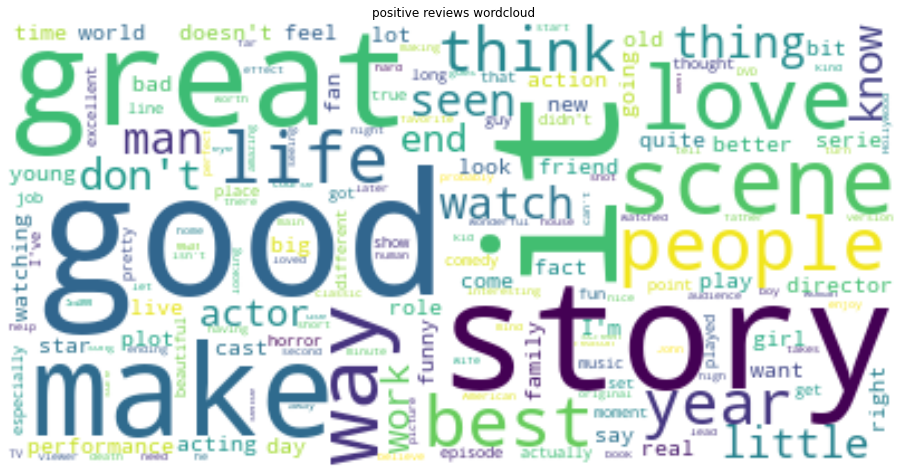

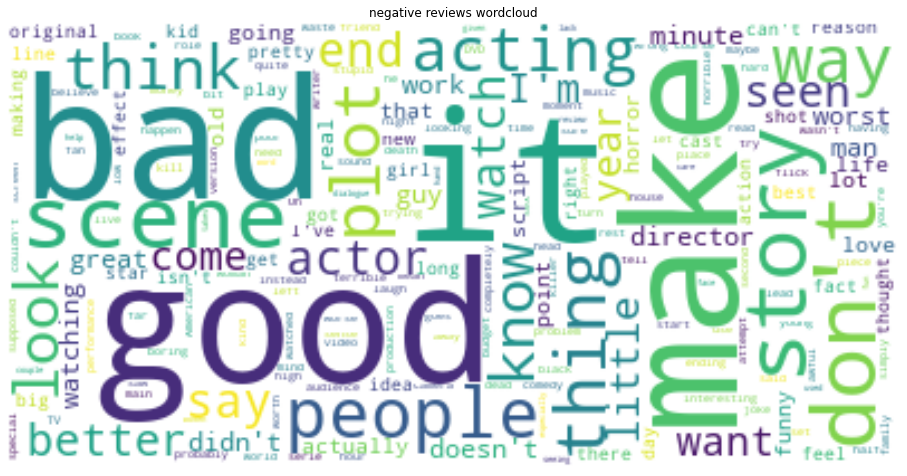

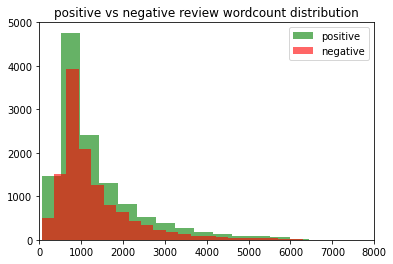

In [ ]:
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction import text
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from wordcloud import WordCloud

stop_words = text.ENGLISH_STOP_WORDS.union(
    [
        "br",
        "ax",
        "character",
        "characters",
        "did",
        "does",
        "don",
        "film",
        "films",
        "movie",
        "movies",
        "really",
        "like",
        "just",
        "time",
    ]
)


def visualize_imdb():
    def wordcloud(txt, title):
        cloud = WordCloud(
            stopwords=stop_words,
            collocations=False,
            max_font_size=80,
            background_color="white",
        ).generate(txt)
        plt.figure(figsize=(16, 12))
        plt.imshow(cloud, interpolation="bilinear")
        plt.axis("off")
        plt.title(title)
        plt.show()

    # top words for + vs -
    imdb_train = get_subset("train")
    pos_txt = "".join(imdb_train["data"][12500:])
    neg_txt = "".join(imdb_train["data"][:12500])
    wordcloud(pos_txt, "positive reviews wordcloud")  # Fig7
    wordcloud(neg_txt, "negative reviews wordcloud")  # Fig8

    # positive review vs negative review word count
    pos = [len(string) for string in imdb_train["data"][12500:]]
    neg = [len(string) for string in imdb_train["data"][:12500]]

    plt.hist(pos, color="g", label="positive", bins=30, alpha=0.6)
    plt.hist(neg, color="r", label="negative", bins=30, alpha=0.6)
    plt.xlim(0, 8000)
    plt.title("positive vs negative review wordcount distribution")
    plt.legend()
    plt.show()  # Fig9

visualize_imdb()

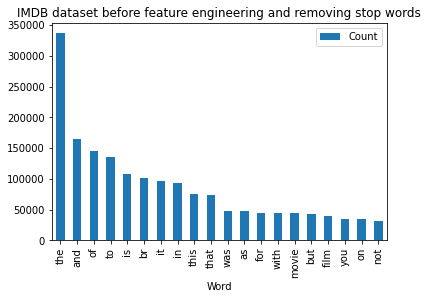

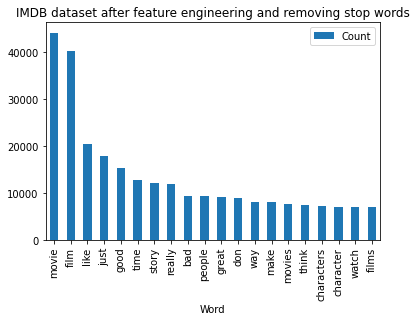

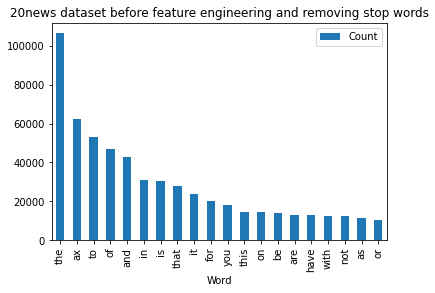

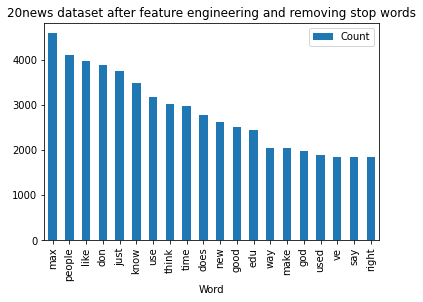

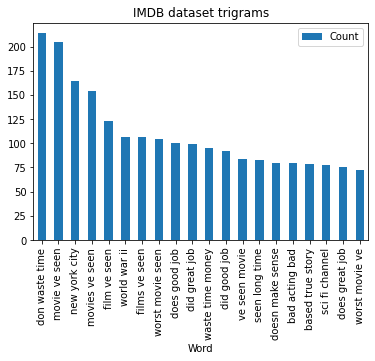

In [ ]:
# --------------------------------------------------------------------------
def sw_before_after():
    # top 20 words before and after removing stop words
    def countplot(x, y, title=""):
        x = np.array(x.sum(axis=0)).flatten()
        x, y = zip(*sorted(zip(x, y), reverse=True))
        df = pd.DataFrame(columns=["Class", "Count"])
        df["Word"] = y
        df["Count"] = x
        df.plot.bar(x="Word", y="Count")
        plt.title(title)
        plt.show()

    imdb_p = Preprocessing(Dataset.imdb_reviews, vectorize=False)
    twenty_news_p = Preprocessing(Dataset.twenty_news, vectorize=False)

    imdb_words_before, imdb_vect_before = imdb_p.custom_vectorizer(
        max_features=20, strip_accents="unicode"
    )
    imdb_words_after, imdb_vect_after = imdb_p.custom_vectorizer(
        max_features=20,
        stop_words=Preprocessing.stop_words,
        strip_accents="unicode",
        lowercase=True,
    )
    twenty_words_before, twenty_vect_before = twenty_news_p.custom_vectorizer(
        max_features=20, strip_accents="unicode"
    )
    twenty_words_after, twenty_vect_after = twenty_news_p.custom_vectorizer(
        max_features=20,
        stop_words=Preprocessing.stop_words,
        strip_accents="unicode",
        lowercase=True,
    )

    countplot(
        imdb_vect_before,
        imdb_words_before,
        "IMDB dataset before feature engineering and removing stop words",
    )  # Fig1
    countplot(
        imdb_vect_after,
        imdb_words_after,
        "IMDB dataset after feature engineering and removing stop words",
    )  # Fig2
    countplot(
        twenty_vect_before,
        twenty_words_before,
        "20news dataset before feature engineering and removing stop words",
    )  # Fig3
    countplot(
        twenty_vect_after,
        twenty_words_after,
        "20news dataset after feature engineering and removing stop words",
    )  # Fig4

    imdb_words_after, imdb_vect_after = imdb_p.custom_vectorizer(
        max_features=20,
        ngram_range=(3, 3),
        stop_words=Preprocessing.stop_words,
        strip_accents="unicode",
        lowercase=True,
    )
    #  Most frequent trigrams IMDB reviews
    countplot(imdb_vect_after, imdb_words_after, "IMDB dataset trigrams")  # Fig5

sw_before_after()

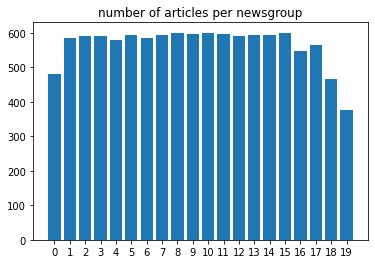

In [ ]:
# --------------------------------------------------------------------------
# total count article per newsgroup
def article_vs_group():
    preproc = Preprocessing(Dataset.twenty_news)
    y = preproc.get_train_test()[1]
    counter = Counter(y)

    labels, values = zip(*counter.items())
    labels, values = zip(*sorted(zip(labels, values)))
    indexes = np.arange(len(labels))
    plt.bar(indexes, values)
    plt.title("number of articles per newsgroup")
    plt.xticks(indexes, labels)
    plt.show()  # Fig6
  
article_vs_group()

Performing analysis on our models and evaluate their performance. 

Preprocess datasets

In [18]:
import numpy as np
import pandas as pd
import operator
from sklearn.model_selection import RandomizedSearchCV, PredefinedSplit
from sklearn.linear_model import LogisticRegression as LR
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt


SEPARATOR = "\n" + 40 * "-" + "\n" + 40 * "-" + "\n"

# Preprocess textual data
imdb_preprocessor = Preprocessing(Dataset.imdb_reviews, verbose=True)
imdb_feature_n = len(imdb_preprocessor.features)
print(SEPARATOR)
twenty_news_preprocessor = Preprocessing(Dataset.twenty_news, verbose=True)
twenty_features_n = len(twenty_news_preprocessor.features)

# Get lemmatized, cleaned and vectorized train and test sets as sparse arrays
(
    X_train_imdb,
    y_train_imdb,
    X_test_imdb,
    y_test_imdb,
) = imdb_preprocessor.get_train_test()
(
    X_train_20news,
    y_train_20news,
    X_test_20news,
    y_test_20news,
) = twenty_news_preprocessor.get_train_test()

Preprocessing the IMDB reviews dataset...

Training set contains 25000 samples
Testing set contains 25000 samples

Vectorizing and lemmatizing dataset...
Number of unique words : 74398
Transforming vector using term frequency–inverse document frequency transformation...

----------------------------------------
----------------------------------------

Preprocessing the 20 newsgroup dataset...

Training set contains 11314 instances
Testing set contains 7532 instances

Vectorizing and lemmatizing dataset...
Number of unique words : 101383
Transforming vector using term frequency–inverse document frequency transformation...


Hyperparameter tuning for multinomial naive bayes

In [ ]:
alphas = np.arange(0.01, 1, 0.4)

# 20news dataset
scores_20news = MultinomialNB.tune_hyperparams(
X_train_20news, y_train_20news, 5, alphas
)
print(scores_20news)
index, max_acc = max(enumerate(scores_20news), key=operator.itemgetter(1)) 
best_alpha_20news = alphas[index]
print("Best alpha for the 20news group datatset", best_alpha_20news)

# IMDB dataset
scores_imdb = MultinomialNB.tune_hyperparams(X_train_imdb, y_train_imdb, 5, alphas)
print(scores_imdb)
index, max_acc = max(enumerate(scores_imdb), key=operator.itemgetter(1))
best_alpha_imdb = alphas[index]
print("Best alpha for the IMDB reviews dataset", best_alpha_imdb)

[0.7645446507515473, 0.7371352785145889, 0.7213969938107869]
Best alpha for the 20news group datatset 0.01
[0.849, 0.86484, 0.865]
Best alpha for the IMDB reviews dataset 0.81


Hyperparameter tuning for logistic regression. We use randomizedsearch instead of gridsearch to tune hyperparams due to each iteration being time consuming. 

In [ ]:
# hyperparameter tuning for Logistic Regression
# 20news dataset
rs = RandomizedSearchCV(
    LR(solver="lbfgs"),
    {
        "max_iter": np.arange(100, 500, 20),
        "C": [0.001, 0.01, 0.1, 1, 10, 100],
    },
    return_train_score=False,
    n_iter=4,
    cv=5,
)
rs.fit(X_train_20news, y_train_20news)
resuts = pd.DataFrame(rs.cv_results_)
print(resuts)
print("best parameters for logistic regression:", rs.best_params_)

print(SEPARATOR)

rs = RandomizedSearchCV(
    LR(solver="lbfgs"),
    {
        "max_iter": np.arange(100, 500, 20),
        "C": [0.001, 0.01, 0.1, 1, 10, 100],
    },
    return_train_score=False,
    n_iter=4,
    cv=5,
)
rs.fit(X_train_imdb, y_train_imdb)
resuts = pd.DataFrame(rs.cv_results_)
print(resuts)
print("best parameters for logistic regression:", rs.best_params_)

   mean_fit_time  std_fit_time  ...  std_test_score  rank_test_score
0      90.036455      2.863872  ...        0.007303                1
1      41.969113      1.431923  ...        0.009369                2
2      10.490058      0.234319  ...        0.007883                3
3       3.919745      0.034606  ...        0.003177                4

[4 rows x 15 columns]
best parameters for logistic regression: {'max_iter': 420, 'C': 10}

----------------------------------------
----------------------------------------



/usr/local/lib/python3.7/dist-packages/sklearn/linear_model/_logistic.py:940: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  extra_warning_msg=_LOGISTIC_SOLVER_CONVERGENCE_MSG)
/usr/local/lib/python3.7/dist-packages/sklearn/linear_model/_logistic.py:940: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression


   mean_fit_time  std_fit_time  ...  std_test_score  rank_test_score
0       7.546388      0.809424  ...        0.007159                3
1       4.732184      1.807788  ...        0.007504                1
2       9.610174      2.522233  ...        0.007186                2
3       0.324345      0.049152  ...        0.008803                4

[4 rows x 15 columns]
best parameters for logistic regression: {'max_iter': 380, 'C': 10}


Hyperparameter tuning using 5-fold CV for the Logistic Regression model we implemented for binary classification on the IMDB dataset.

In [33]:
lreg = LogisticRegression()
accuracies, params = lreg.tune_hyperparams(X_train_imdb, y_train_imdb, 5)
print(accuracies)
print(params)
best_index = np.argmax(accuracies)
print("Best hyperparameters for logistic regression on the IMDB dataset:", params[best_index])

[0.75212, 0.80196, 0.80192, 0.8310000000000001, 0.5201199999999999, 0.88056, 0.50736, 0.7806]
[(0.1, 100), (0.1, 1000), (1, 100), (1, 1000), (10, 100), (10, 1000), (100, 100), (100, 1000)]
Best hyperparameters for logistic regression on the IMDB dataset: (10, 1000)


1- Conduct multiclass classification on the 20 news group dataset, and binary classification on the IMDB Reviews.


In [2]:
def evaluate_model(model, dataset, sets=None, verbose=True, show_plot=True, **kwargs):
    clf = model(**kwargs)
    if dataset == Dataset.twenty_news:
        X_train, y_train, X_test, y_test = (
            X_train_20news,
            y_train_20news,
            X_test_20news,
            y_test_20news,
        )
        rg = 20
    elif dataset == Dataset.imdb_reviews:
        X_train, y_train, X_test, y_test = (
            X_train_imdb,
            y_train_imdb,
            X_test_imdb,
            y_test_imdb,
        )
        rg = 2
    else:
        raise ValueError("Dataset doesn't exist")
    if sets is not None:
        X_train, y_train, X_test, y_test = sets
    clf.fit(X_train, y_train)
    pred = clf.predict(X_test)
    acc = accuracy_score(y_test, pred)
    f1 = f1_score(pred, y_test, average="weighted")
    if verbose:
        msg1 = "Accuracy of the {} model on the {} dataset: {}".format(
            model, dataset, acc
        )
        msg2 = "F1 score of the {} model on the {} dataset: {}".format(
            model, dataset, f1
        )
        print(msg1)
        print(msg2)
    if show_plot:
        con_matrix = confusion_matrix(y_test, pred)
        df_cm = pd.DataFrame(con_matrix, range(rg), range(rg))
        sns.heatmap(df_cm, annot=True)
        plt.ylabel("Predicted Class")
        plt.xlabel("True Class")
        plt.show()  # Fig10
    return acc

Accuracy of the <class '__main__.MultinomialNB'> model on the Dataset.imdb_reviews dataset: 0.8284
F1 score of the <class '__main__.MultinomialNB'> model on the Dataset.imdb_reviews dataset: 0.8287792558092476


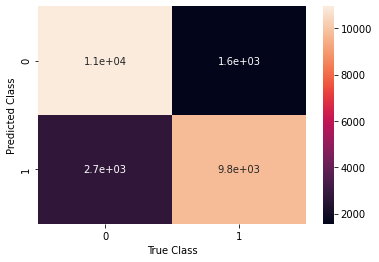

Accuracy of the <class '__main__.MultinomialNB'> model on the Dataset.twenty_news dataset: 0.7007434944237918
F1 score of the <class '__main__.MultinomialNB'> model on the Dataset.twenty_news dataset: 0.7064311781788515


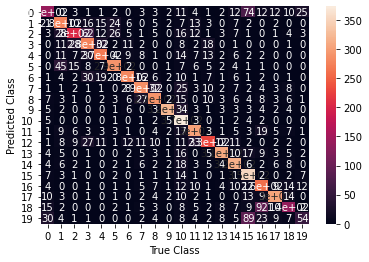

Accuracy of the <class 'sklearn.linear_model._logistic.LogisticRegression'> model on the Dataset.imdb_reviews dataset: 0.87124
F1 score of the <class 'sklearn.linear_model._logistic.LogisticRegression'> model on the Dataset.imdb_reviews dataset: 0.8712533975842846


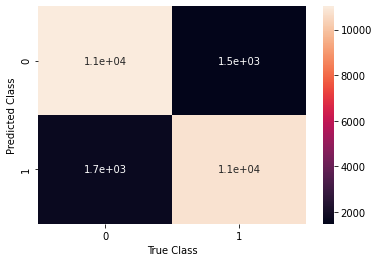

Accuracy of the <class 'sklearn.linear_model._logistic.LogisticRegression'> model on the Dataset.twenty_news dataset: 0.6907859798194371
F1 score of the <class 'sklearn.linear_model._logistic.LogisticRegression'> model on the Dataset.twenty_news dataset: 0.6902758269526218


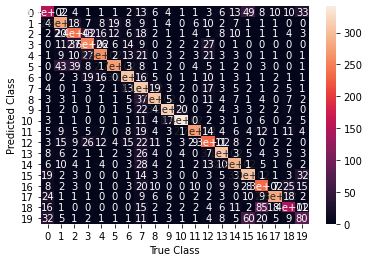

Accuracy of the <class '__main__.LogisticRegression'> model on the Dataset.imdb_reviews dataset: 0.8742
F1 score of the <class '__main__.LogisticRegression'> model on the Dataset.imdb_reviews dataset: 0.8742023044969348


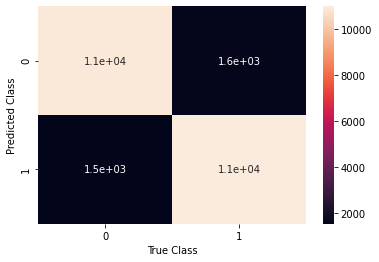

In [34]:
best_alpha_imdb = 0.81
best_alpha_20news = 0.01


def part1():
    evaluate_model(MultinomialNB, Dataset.imdb_reviews, alpha=best_alpha_imdb)
    evaluate_model(MultinomialNB, Dataset.twenty_news, alpha=best_alpha_20news)
    evaluate_model(LR, Dataset.imdb_reviews, C=10, max_iter=380)
    evaluate_model(LR, Dataset.twenty_news, C=10, max_iter=420)
    evaluate_model(
        LogisticRegression, Dataset.imdb_reviews, learning_rate=10, num_iters=1000
    )
part1()

ROC curve of the Logistic regression classifier on the IMDB reviews dataset.

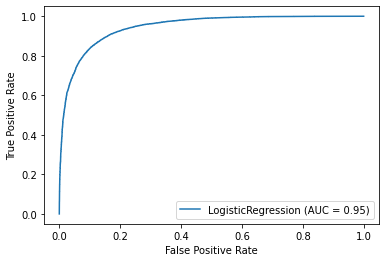

In [16]:
from sklearn.metrics import plot_roc_curve

clf = LR(C=10, max_iter=380)
clf.fit(X_train_imdb, y_train_imdb)
plot_roc_curve(clf, X_test_imdb, y_test_imdb)
plt.show()

With a plot, compare the accuracy of the two models as a function of the size of dataset (by controlling the training size).


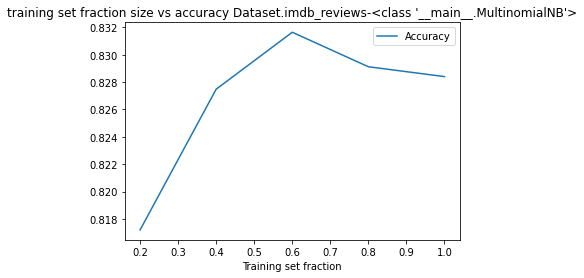

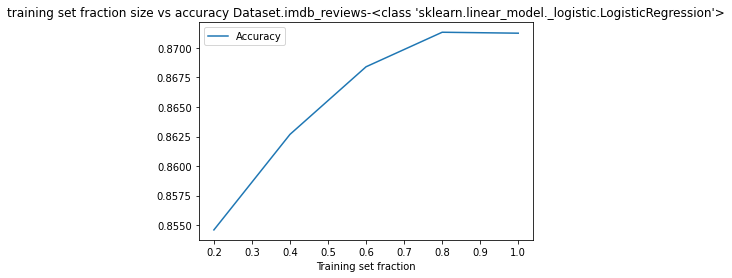

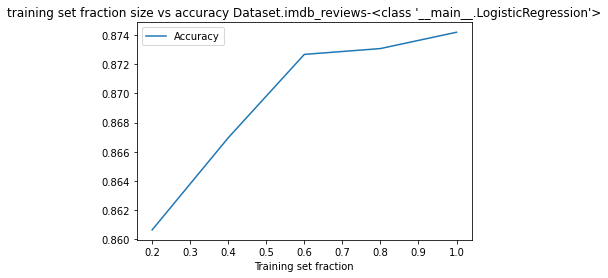

In [12]:
best_alpha_imdb = 0.81
best_alpha_20news = 0.01

# ---------------------------------------------------------------------------
def part2():
    def dataset_size_acc(dataset, model, **kwargs):
        fractions = [0.2, 0.4, 0.6, 0.8, 1]
        accuracies = []

        for frac in fractions:
            preprocessor = Preprocessing(dataset, frac=frac)
            set_ = preprocessor.get_train_test()
            acc = evaluate_model(
                model, dataset, sets=set_, verbose=False, show_plot=False, **kwargs
            )
            accuracies.append(acc)
        df = pd.DataFrame(columns=["Training set fraction", "Accuracy"])
        df["Training set fraction"] = fractions
        df["Accuracy"] = accuracies
        df.plot.line(x="Training set fraction", y="Accuracy")
        plt.title("training set fraction size vs accuracy {}-{}".format(dataset, model))
        plt.show()

    dataset_size_acc(Dataset.imdb_reviews, MultinomialNB, alpha=best_alpha_imdb)
    # dataset_size_acc(Dataset.twenty_news, MultinomialNB, alpha=best_alpha_20news)
    dataset_size_acc(Dataset.imdb_reviews, LR, C=10, max_iter=380)
    # dataset_size_acc(Dataset.twenty_news, LR, C=10, max_iter=420)
    dataset_size_acc(Dataset.imdb_reviews, LogisticRegression, learning_rate=10, num_iters=1000)
part2()

Compare the accuracy of models with reduced features

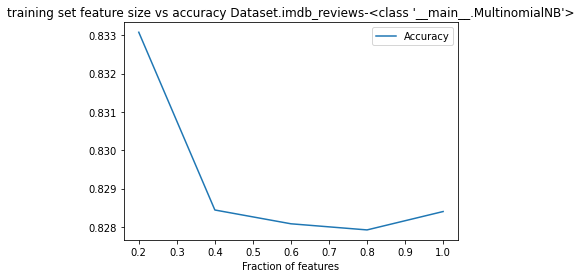

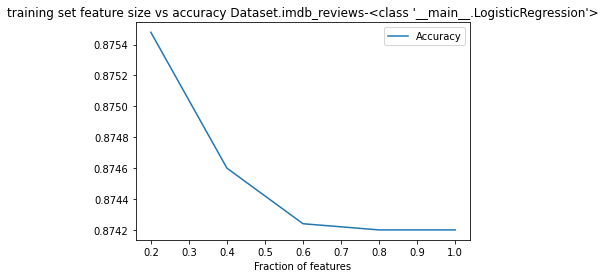

In [13]:
best_alpha_imdb = 0.81
best_alpha_20news = 0.01

def part3():
    def feature_size_acc(dataset, model, **kwargs):
        fractions = [0.2, 0.4, 0.6, 0.8, 1]
        accuracies = []

        for frac in fractions:
            if dataset == Dataset.imdb_reviews:
                dataset_features = imdb_feature_n
            elif dataset == Dataset.twenty_news:
                dataset_features = twenty_features_n
            num_features = int(frac * dataset_features)
            preprocessor = Preprocessing(dataset, max_features=num_features)
            set_ = preprocessor.get_train_test()
            acc = evaluate_model(
                model, dataset, set_, verbose=False, show_plot=False, **kwargs
            )
            accuracies.append(acc)
        df = pd.DataFrame(columns=["Fraction of features", "Accuracy"])
        df["Fraction of features"] = fractions
        df["Accuracy"] = accuracies
        df.plot.line(x="Fraction of features", y="Accuracy")
        plt.title("training set feature size vs accuracy {}-{}".format(dataset, model))
        plt.show()

    feature_size_acc(Dataset.imdb_reviews, MultinomialNB, alpha=best_alpha_imdb)
    # feature_size_acc(Dataset.twenty_news, MultinomialNB, alpha=best_alpha_20news)
    feature_size_acc(Dataset.imdb_reviews, LogisticRegression, learning_rate=10, num_iters=1000)
    # feature_size_acc(Dataset.twenty_news, LR)


part3()